# 08 — Gradient Boosting

A trilha principal terminou no notebook 07 com uma **random forest** ajustada: **MAE de 0,303** no teste (≈ US$ 30.300). Este notebook extra apresenta a família de modelos que costuma ser a **mais forte para dados em tabela**: o **gradient boosting**.

Você vai aprender:
- A diferença entre **bagging** (random forest) e **boosting**
- Como o boosting funciona por dentro, **construindo um à mão**
- A **taxa de aprendizado** (*learning rate*) e por que correções pequenas funcionam melhor
- Por que, no boosting, **árvores demais causam overfitting**
- **Parada antecipada** (*early stopping*)
- O `HistGradientBoostingRegressor` do scikit-learn
- Ajustar hiperparâmetros quando eles **realmente** importam

> ⏱️ A busca de hiperparâmetros da seção 8 leva **cerca de 5 minutos**. O notebook inteiro leva uns 7 minutos.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint

# Ferramentas novas deste notebook:
from sklearn.ensemble import HistGradientBoostingRegressor   # gradient boosting rápido do scikit-learn
from scipy.stats import loguniform                           # sorteia valores em escala logarítmica

from atributos import criar_derivados, criar_dist_cidade     # as funções do notebook 07

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# A mesma divisão de sempre:
# - teste (20%), guardado até a seção 10;
# - treino/validação (60%/20%), para os experimentos didáticos das seções 2 a 7;
# - X_train_full (80%), para a validação cruzada.
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

kfold = KFold(n_splits=5, shuffle=True, random_state=42)   # as mesmas dobras dos notebooks 05 e 06

## 🎓 Conceito: bagging × boosting

Os dois métodos combinam **muitas árvores**, mas de formas opostas:

| | **Bagging** (random forest, notebook 04) | **Boosting** (este notebook) |
|---|---|---|
| Como as árvores são treinadas | **Independentes**, ao mesmo tempo | **Em sequência**, uma depois da outra |
| O que cada árvore aprende | O preço, com uma amostra sorteada dos dados | **O erro** que as árvores anteriores deixaram |
| Tipo de árvore | **Profundas** (com overfitting individual) | **Rasas** (simples, "fracas") |
| Como combina | **Média** das previsões | **Soma** das correções |
| Mais árvores... | Nunca causam overfitting | **Podem causar** overfitting |

**Analogia:** a random forest é como pedir a opinião de 100 especialistas independentes e tirar a média. O boosting é como um aluno que faz a prova, confere o que errou, estuda **só aquilo**, refaz a prova, confere de novo... Cada rodada corrige um pouco do que faltava.

O "gradient" do nome vem da matemática por trás: cada árvore nova segue a direção que mais reduz o erro (o **gradiente**). Para o erro quadrático, essa direção é exatamente o **resíduo** (`real − previsto`), aquele conceito do notebook 02.

## 2. Boosting à mão

A melhor forma de entender é construir um. Vamos usar só a renda (`MedInc`) e árvores **minúsculas** (profundidade 2, ou seja, 4 folhas cada):

1. Começa prevendo a **média** para todas as casas.
2. Calcula o **resíduo** de cada casa (o que falta acertar).
3. Treina uma árvore pequena para prever **o resíduo**.
4. Soma a previsão dessa árvore (multiplicada pela **taxa de aprendizado**) à previsão atual.
5. Volta ao passo 2.

In [2]:
def boosting_a_mao(X_tr, y_tr, X_va, y_va, n_arvores, taxa, profundidade, guardar_em=()):
    """Gradient boosting simplificado. Devolve o MAE de treino e validação após cada árvore."""
    # Passo 1: a previsão inicial é a média do treino, para todas as casas.
    previsao_tr = np.full(len(y_tr), y_tr.mean())   # np.full cria um array repetindo um valor
    previsao_va = np.full(len(y_va), y_tr.mean())

    historico = []
    previsoes_guardadas = {}
    for i in range(1, n_arvores + 1):
        residuo = y_tr - previsao_tr                                  # Passo 2: o que falta acertar
        arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=42)
        arvore.fit(X_tr, residuo)                                     # Passo 3: aprende o RESÍDUO
        previsao_tr = previsao_tr + taxa * arvore.predict(X_tr)       # Passo 4: soma a correção
        previsao_va = previsao_va + taxa * arvore.predict(X_va)

        historico.append({
            "árvores": i,
            "MAE treino": mean_absolute_error(y_tr, previsao_tr),
            "MAE validação": mean_absolute_error(y_va, previsao_va),
        })
        if i in guardar_em:
            previsoes_guardadas[i] = previsao_va.copy()

    return pd.DataFrame(historico).set_index("árvores"), previsoes_guardadas


etapas = [1, 3, 10, 50]
hist_01, previsoes_etapas = boosting_a_mao(
    X_train[["MedInc"]], y_train, X_val[["MedInc"]], y_val,
    n_arvores=200, taxa=0.1, profundidade=2, guardar_em=etapas,
)
hist_01.loc[[1, 3, 10, 50, 100, 200]].round(3)

,MAE treino,MAE validação
árvores,,
1,0.869,0.883
3,0.804,0.816
10,0.680,0.690
50,0.610,0.616
100,0.607,0.615
200,0.603,0.614


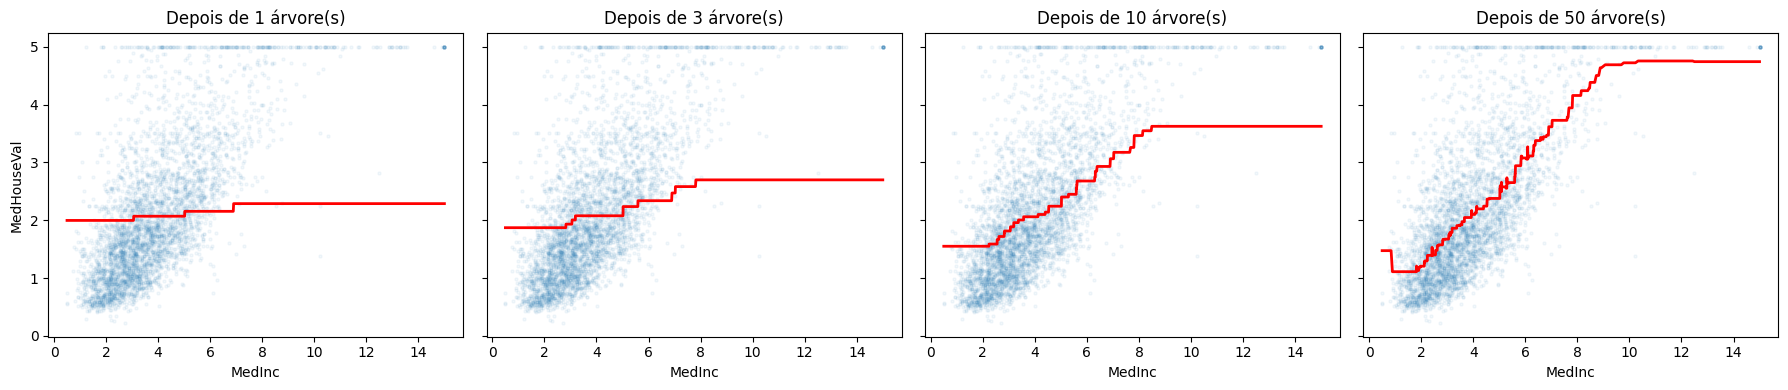

In [3]:
# Como a curva de previsão evolui conforme as árvores são somadas?
ordem = np.argsort(X_val["MedInc"].values)   # posições que ordenam as casas pela renda (para desenhar a linha)
renda_ordenada = X_val["MedInc"].values[ordem]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, n in zip(axes, etapas):
    ax.scatter(X_val["MedInc"], y_val, alpha=0.05, s=5)
    ax.plot(renda_ordenada, previsoes_etapas[n][ordem], color="red", linewidth=2)
    ax.set_title(f"Depois de {n} árvore(s)")
    ax.set_xlabel("MedInc")
axes[0].set_ylabel("MedHouseVal")
plt.tight_layout()
plt.show()

**Conclusão:** a previsão começa quase plana, perto da média, e vai sendo **esculpida** aos poucos:
- **1 árvore:** um degrau tímido. A taxa de 0,1 faz a árvore corrigir só 10% do que ela "acha" que deveria.
- **3 e 10 árvores:** a curva vai se inclinando e ganhando forma.
- **50 árvores:** a curva já acompanha a tendência dos dados, com a aceleração para rendas altas que vimos na dependência parcial do notebook 07.

O MAE de validação caiu de **0,883** (1 árvore) para **0,614** (200 árvores). Cada árvore sozinha é muito fraca (só 4 folhas!), mas a **soma** de muitas pequenas correções forma um modelo bom.

## 🎓 Conceito: taxa de aprendizado (learning rate)

A **taxa de aprendizado** controla **quanto** de cada correção é aplicado. Com taxa 1,0, cada árvore corrige o erro "inteiro" que encontrou. Com 0,1, corrige só 10% e deixa o resto para as próximas árvores.

Por que corrigir pouco seria melhor? Porque cada árvore é treinada no **treino** e aprende tanto o padrão real quanto um pouco do **ruído**. Se cada árvore corrige muito, o modelo absorve esse ruído rápido. Com passos pequenos, os ruídos das várias árvores tendem a se cancelar, e só o padrão que **se repete** se acumula.

**Analogia:** é como descer uma montanha no escuro. Passos grandes chegam rápido perto do fundo, mas passam do ponto. Passos pequenos demoram mais, mas param no lugar certo.

## 3. Comparando taxas de aprendizado

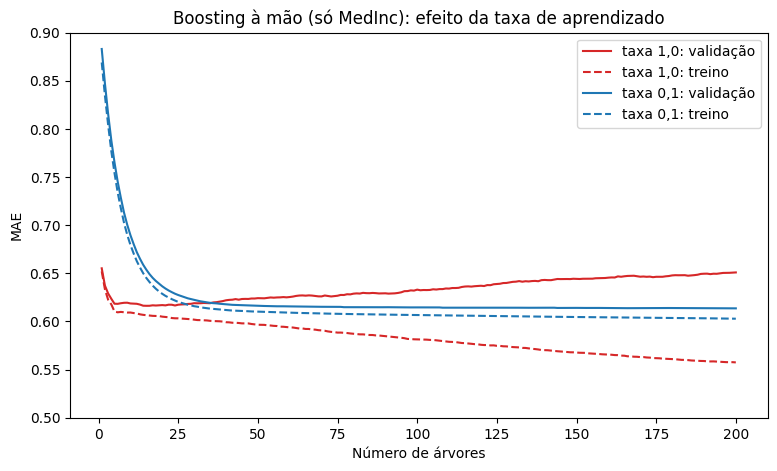

taxa 1,0: melhor validação com  15 árvores (MAE 0.616); com 200 árvores: 0.651
taxa 0,1: melhor validação com 200 árvores (MAE 0.614); com 200 árvores: 0.614


In [4]:
hist_10, _ = boosting_a_mao(
    X_train[["MedInc"]], y_train, X_val[["MedInc"]], y_val,
    n_arvores=200, taxa=1.0, profundidade=2,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(hist_10.index, hist_10["MAE validação"], label="taxa 1,0: validação", color="tab:red")
ax.plot(hist_10.index, hist_10["MAE treino"], label="taxa 1,0: treino", color="tab:red", linestyle="--")
ax.plot(hist_01.index, hist_01["MAE validação"], label="taxa 0,1: validação", color="tab:blue")
ax.plot(hist_01.index, hist_01["MAE treino"], label="taxa 0,1: treino", color="tab:blue", linestyle="--")
ax.set_xlabel("Número de árvores")
ax.set_ylabel("MAE")
ax.set_ylim(0.5, 0.9)
ax.set_title("Boosting à mão (só MedInc): efeito da taxa de aprendizado")
ax.legend()
plt.show()

# idxmin devolve o ÍNDICE (aqui, o número de árvores) onde está o menor valor.
for nome, hist in [("taxa 1,0", hist_10), ("taxa 0,1", hist_01)]:
    melhor = hist["MAE validação"].idxmin()
    print(f"{nome}: melhor validação com {melhor:>3} árvores (MAE {hist['MAE validação'].min():.3f}); "
          f"com 200 árvores: {hist['MAE validação'].iloc[-1]:.3f}")

**Conclusão:**
- **Taxa 1,0 (vermelho):** cai muito rápido nas primeiras árvores e atinge o melhor resultado com apenas **15 árvores** (0,616). Depois, o erro de validação **sobe** (até 0,651 com 200 árvores), enquanto o do treino continua caindo. É **overfitting**: as correções grandes passaram a decorar ruído.
- **Taxa 0,1 (azul):** começa devagar, mas melhora de forma **suave e contínua** e termina com o menor erro (0,614), ainda melhorando com 200 árvores.

Lembre do notebook 04: na random forest, mais árvores **nunca** causavam overfitting. **No boosting, causam**, porque cada árvore nova se ajusta mais ao treino. Por isso o número de árvores e a taxa de aprendizado precisam ser escolhidos **juntos**: quanto menor a taxa, mais árvores são necessárias.

## 4. Boosting à mão com todas as colunas

Com uma só coluna, o modelo é limitado. Vamos usar as 8 colunas e árvores um pouco maiores (profundidade 3, 8 folhas cada).

In [5]:
inicio = time.time()
hist_todas, _ = boosting_a_mao(X_train, y_train, X_val, y_val, n_arvores=300, taxa=0.1, profundidade=3)
print(f"Tempo: {time.time() - inicio:.0f} s")
hist_todas.iloc[[-1]].round(3)   # a última linha: depois das 300 árvores

Tempo: 7 s


,MAE treino,MAE validação
árvores,,
300,0.302,0.34


**Conclusão:** nosso boosting caseiro, com **300 árvores de apenas 8 folhas** e cerca de 25 linhas de código, chegou a **MAE de 0,340** na validação. É quase o mesmo da random forest do notebook 04 (0,335), que usa 100 árvores **gigantes**, com milhares de folhas cada.

Isso mostra a força da ideia: muitos modelos fracos, cada um corrigindo os erros dos anteriores, formam um modelo forte. A versão profissional do scikit-learn, a seguir, traz várias melhorias sobre essa ideia básica.

## 🎓 Conceito: HistGradientBoostingRegressor

O scikit-learn tem duas implementações de gradient boosting:
- `GradientBoostingRegressor`: a versão clássica, parecida com a nossa. Fica lenta com muitos dados.
- **`HistGradientBoostingRegressor`**: a versão moderna e **muito mais rápida**, inspirada na biblioteca LightGBM.

O "Hist" vem de **histograma**. Antes de treinar, cada coluna é dividida em até **255 faixas** de valores, como nos histogramas do notebook 01. Para escolher uma pergunta, a árvore testa só os limites entre as faixas, e não todos os valores possíveis. Isso acelera muito o treino, quase sem perder qualidade.

Além disso, ele:
- Usa árvores limitadas por **número de folhas** (`max_leaf_nodes`, padrão 31), e não só por profundidade.
- Tem **parada antecipada** embutida (seção 7).
- Aceita **valores ausentes** (NaN) sem pré-processamento, um bônus útil em dados reais.

## 5. HistGradientBoosting com as configurações padrão

In [6]:
def com_atributos(modelo):
    """Coloca um modelo no fim do pipeline de atributos (derivados + distância até a cidade)."""
    return Pipeline([
        ("derivados", FunctionTransformer(criar_derivados)),
        ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
        ("modelo", modelo),
    ])


placar = {}


def avaliar_cv(nome, modelo):
    """Validação cruzada com as 5 dobras de sempre; guarda e mostra o resultado."""
    cv = cross_validate(modelo, X_train_full, y_train_full, cv=kfold,
                        scoring="neg_mean_absolute_error", return_train_score=True)
    placar[nome] = {
        "MAE validação": -cv["test_score"].mean(),
        "± desvio": cv["test_score"].std(),
        "MAE treino": -cv["train_score"].mean(),
        "tempo de treino (s)": cv["fit_time"].mean(),   # tempo médio para treinar UM modelo
        "_por_dobra": -cv["test_score"],
    }
    r = placar[nome]
    print(f"{nome:<42} MAE {r['MAE validação']:.4f} ± {r['± desvio']:.4f}   "
          f"(treino {r['MAE treino']:.3f}, {r['tempo de treino (s)']:.1f} s por modelo)")


# Referência: a random forest final do notebook 07.
avaliar_cv("Random forest ajustada (nb 06/07)",
           com_atributos(RandomForestRegressor(n_estimators=100, max_features=0.75, n_jobs=-1, random_state=42)))

# HistGradientBoosting com todas as configurações padrão:
avaliar_cv("HistGB padrão, sem atributos", HistGradientBoostingRegressor(random_state=42))
avaliar_cv("HistGB padrão, com atributos", com_atributos(HistGradientBoostingRegressor(random_state=42)))

Random forest ajustada (nb 06/07)          MAE 0.3116 ± 0.0045   (treino 0.116, 1.2 s por modelo)


HistGB padrão, sem atributos               MAE 0.3167 ± 0.0075   (treino 0.270, 0.2 s por modelo)


HistGB padrão, com atributos               MAE 0.3063 ± 0.0053   (treino 0.259, 0.2 s por modelo)


**Conclusão:** sem ajustar nada, o `HistGradientBoostingRegressor` com os atributos chegou a **MAE de 0,306**, melhor que a random forest **depois** de todo o ajuste do notebook 06 (0,312). E treina **cerca de 6× mais rápido**: 0,2 segundo por modelo, contra 1,2 segundo da floresta.

Os atributos do notebook 03 continuam ajudando (0,317 → 0,306): engenharia de atributos vale para qualquer modelo.

Repare também no **MAE de treino**: 0,26 no boosting contra 0,12 na floresta. O boosting tem **muito menos overfitting**, porque suas árvores são pequenas e cada correção é parcial.

## 6. O número de árvores e a taxa de aprendizado, juntos

24 modelos treinados em 42 s


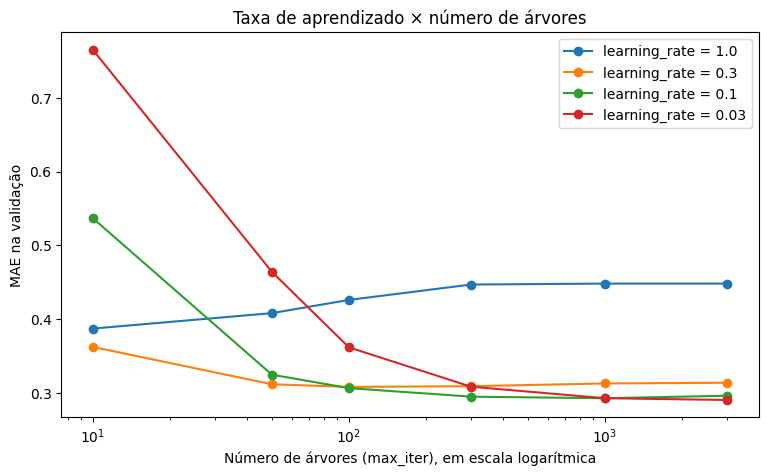

,1.00,0.30,0.10,0.03
árvores,,,,
10,0.387,0.362,0.537,0.765
50,0.408,0.312,0.325,0.464
100,0.426,0.308,0.307,0.362
300,0.447,0.309,0.295,0.309
1000,0.448,0.313,0.293,0.293
3000,0.448,0.314,0.296,0.291


In [7]:
# No HistGradientBoosting, o número de árvores se chama max_iter ("número máximo de iterações").
# early_stopping=False desliga a parada antecipada, para vermos o efeito de cada número de árvores.
taxas = [1.0, 0.3, 0.1, 0.03]
numeros_de_arvores = [10, 50, 100, 300, 1000, 3000]
curvas = {}

inicio = time.time()
for taxa in taxas:
    maes_val = []
    for n in numeros_de_arvores:
        modelo = com_atributos(HistGradientBoostingRegressor(
            learning_rate=taxa, max_iter=n, early_stopping=False, random_state=42))
        modelo.fit(X_train, y_train)
        maes_val.append(mean_absolute_error(y_val, modelo.predict(X_val)))
    curvas[taxa] = maes_val
print(f"24 modelos treinados em {time.time() - inicio:.0f} s")

fig, ax = plt.subplots(figsize=(9, 5))
for taxa, maes_val in curvas.items():
    ax.plot(numeros_de_arvores, maes_val, marker="o", label=f"learning_rate = {taxa}")
ax.set_xscale("log")   # escala logarítmica: 10, 100, 1000 ficam igualmente espaçados
ax.set_xlabel("Número de árvores (max_iter), em escala logarítmica")
ax.set_ylabel("MAE na validação")
ax.set_title("Taxa de aprendizado × número de árvores")
ax.legend()
plt.show()

pd.DataFrame(curvas, index=pd.Index(numeros_de_arvores, name="árvores")).round(3)

**Conclusão:** cada taxa de aprendizado tem o seu **número ideal de árvores**:
- **1,0:** o melhor resultado vem logo com 10 árvores (0,387). Depois disso, só piora, chegando a 0,448: overfitting rápido.
- **0,3:** melhor perto de 100 árvores (0,308), e depois piora devagar.
- **0,1:** melhor perto de 1.000 árvores (0,293).
- **0,03:** ainda melhorando com 3.000 árvores (0,291), mas é a mais lenta.

A regra prática: **taxas menores dão resultados um pouco melhores, mas precisam de mais árvores** (e de mais tempo). E, para qualquer taxa, árvores demais acabam piorando.

Mas como saber o número certo de árvores sem testar todos?

## 🎓 Conceito: parada antecipada (early stopping)

A ideia é simples:
1. Separe uma pequena parte do treino (por padrão, 10%) como **validação interna**.
2. Adicione árvores uma a uma e meça o erro nessa validação interna.
3. Se o erro **não melhorar** por um certo número de árvores seguidas (`n_iter_no_change`), **pare**.

Assim o modelo descobre sozinho quantas árvores usar. Basta dar um `max_iter` alto, que funciona como um limite de segurança.

É como estudar para uma prova fazendo simulados: quando suas notas nos simulados param de subir, continuar estudando o mesmo material não ajuda mais.

## 7. Parada antecipada na prática

In [8]:
modelo_parada = com_atributos(HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=3000,              # limite máximo: o modelo provavelmente vai parar antes
    early_stopping=True,        # liga a parada antecipada
    validation_fraction=0.1,    # 10% do treino viram validação interna
    n_iter_no_change=20,        # para se passar 20 árvores sem melhorar
    random_state=42,
))
modelo_parada.fit(X_train, y_train)

# n_iter_ (com "_" no final: algo que o modelo aprendeu) diz quantas árvores ele realmente usou.
print(f"Árvores usadas: {modelo_parada['modelo'].n_iter_} de no máximo 3000")
print(f"MAE na validação: {mean_absolute_error(y_val, modelo_parada.predict(X_val)):.3f}")

Árvores usadas: 215 de no máximo 3000
MAE na validação: 0.302


**Conclusão:** o modelo parou sozinho depois de **215 árvores**, com MAE de **0,302** na validação. É perto do que encontramos na seção 6 testando à mão (0,293–0,307 entre 100 e 1.000 árvores), mas com **um único treino** e sem precisar escolher o número de árvores.

Ele parou um pouco antes do ideal porque sua validação interna é pequena (10% do treino) e um pouco "ruidosa". Mesmo assim, a parada antecipada é a forma prática de escolher o número de árvores. Na busca de hiperparâmetros a seguir, ela fica sempre ligada.

## 8. Ajuste de hiperparâmetros (agora vale a pena!)

No notebook 06, o ajuste quase não mudou a random forest (−0,004). O boosting é diferente: ele é **sensível** aos hiperparâmetros. Os principais do `HistGradientBoostingRegressor` são:

| Hiperparâmetro | O que controla |
|---|---|
| `learning_rate` | Tamanho de cada correção |
| `max_leaf_nodes` | Número máximo de folhas por árvore (a "complexidade" de cada árvore) |
| `min_samples_leaf` | Mínimo de casas por folha |
| `l2_regularization` | "Freio" nos valores das folhas: valores maiores deixam as correções mais conservadoras |

🎓 **Distribuição log-uniforme:** para `learning_rate` e `l2_regularization`, a escala importante é a **ordem de grandeza** (0,01, 0,1 ou 1?). Se sorteássemos de forma uniforme entre 0,01 e 0,3, cerca de **2/3** dos valores cairiam entre 0,1 e 0,3, e a região de 0,01 a 0,1 seria pouco explorada. A `loguniform` dá a mesma chance a cada ordem de grandeza: neste intervalo, cerca de 2/3 dos valores ficam **abaixo** de 0,1.

In [9]:
print("uniform-like  (0,01 a 0,3):", np.sort(np.random.default_rng(0).uniform(0.01, 0.3, 8)).round(3))
print("loguniform    (0,01 a 0,3):", np.sort(loguniform(0.01, 0.3).rvs(8, random_state=0)).round(3))

uniform-like  (0,01 a 0,3): [0.015 0.022 0.088 0.186 0.195 0.222 0.246 0.275]
loguniform    (0,01 a 0,3): [0.042 0.044 0.064 0.065 0.078 0.09  0.114 0.208]


**Conclusão:** no sorteio uniforme, 5 dos 8 valores ficaram acima de 0,18. No log-uniforme, 6 dos 8 ficaram abaixo de 0,1. Para a taxa de aprendizado, o log-uniforme explora melhor os valores pequenos, que a seção 6 mostrou serem os mais promissores.

In [10]:
distribuicoes = {
    "modelo__learning_rate": loguniform(0.01, 0.3),
    "modelo__max_leaf_nodes": randint(15, 128),
    "modelo__min_samples_leaf": randint(5, 100),
    "modelo__l2_regularization": loguniform(0.001, 10),
}

busca = RandomizedSearchCV(
    com_atributos(HistGradientBoostingRegressor(
        max_iter=3000, early_stopping=True, n_iter_no_change=30, random_state=42)),
    param_distributions=distribuicoes,
    n_iter=30,                       # 30 combinações × 5 dobras = 150 modelos
    cv=kfold,
    scoring="neg_mean_absolute_error",
    random_state=42,
    return_train_score=True,
)

inicio = time.time()
busca.fit(X_train_full, y_train_full)
print(f"Tempo: {time.time() - inicio:.0f} s")

# Mostra os melhores hiperparâmetros de forma legível.
for nome, valor in busca.best_params_.items():
    print(f"  {nome.replace('modelo__', ''):<18} = {valor:.4g}")   # :.4g = 4 algarismos significativos
print(f"Melhor MAE (validação cruzada): {-busca.best_score_:.4f}")

Tempo: 353 s
  l2_regularization  = 0.2975
  learning_rate      = 0.03672
  max_leaf_nodes     = 78
  min_samples_leaf   = 7
Melhor MAE (validação cruzada): 0.2909


In [11]:
resultados = pd.DataFrame(busca.cv_results_).sort_values("rank_test_score")
tabela = pd.DataFrame({
    "learning_rate": resultados["param_modelo__learning_rate"].astype(float),
    "max_leaf_nodes": resultados["param_modelo__max_leaf_nodes"],
    "min_samples_leaf": resultados["param_modelo__min_samples_leaf"],
    "l2_regularization": resultados["param_modelo__l2_regularization"].astype(float),
    "MAE val": -resultados["mean_test_score"],
    "MAE treino": -resultados["mean_train_score"],
})
print(f"Pior combinação: MAE {tabela['MAE val'].max():.4f}   Melhor: {tabela['MAE val'].min():.4f}")
tabela.head(8).round(4)

Pior combinação: MAE 0.3159   Melhor: 0.2909


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE val,MAE treino
8,0.0367,78,7,0.2975,0.2909,0.1620
14,0.0586,120,8,0.0177,0.2910,0.1280
13,0.0241,118,8,4.3379,0.2917,0.1645
12,0.0539,61,39,0.0031,0.2932,0.1883
3,0.0121,102,34,0.4014,0.2935,0.1954
7,0.0221,76,51,7.8528,0.2937,0.1957
18,0.0375,96,57,0.0200,0.2954,0.1861
11,0.0219,106,64,0.0012,0.2955,0.1951


**Conclusão:** a melhor combinação chegou a **MAE de 0,291** na validação cruzada. São −0,015 em relação ao boosting padrão (0,306): quase **4× a melhoria** que o ajuste trouxe para a random forest no notebook 06.

A diferença entre a melhor e a pior combinação sorteada (0,291 contra 0,316) também é bem maior que no notebook 06. Isso confirma que, no boosting, **os hiperparâmetros importam**.

O vencedor combina uma **taxa de aprendizado baixa** (~0,037) com árvores **maiores** que o padrão (78 folhas contra 31). Pela seção 6, isso faz sentido: taxas baixas generalizam melhor, e a parada antecipada se encarrega de usar árvores suficientes.

## 9. O boosting vence a random forest de forma consistente?

In [12]:
melhor_boosting = busca.best_estimator_
avaliar_cv("HistGB ajustado", melhor_boosting)

# Comparação pareada (notebook 05): dobra a dobra, contra a random forest final.
diferencas = placar["HistGB ajustado"]["_por_dobra"] - placar["Random forest ajustada (nb 06/07)"]["_por_dobra"]
print(f"\nDiferença por dobra (boosting − floresta): {diferencas.round(4)}")
print(f"O boosting venceu em {(diferencas < 0).sum()} de 5 dobras.")

pd.DataFrame(placar).T.drop(columns="_por_dobra").astype(float).round(4)

HistGB ajustado                            MAE 0.2909 ± 0.0046   (treino 0.162, 2.5 s por modelo)

Diferença por dobra (boosting − floresta): [-0.0207 -0.0241 -0.0142 -0.0203 -0.0241]
O boosting venceu em 5 de 5 dobras.


,MAE validação,± desvio,MAE treino,tempo de treino (s)
Random forest ajustada (nb 06/07),0.3116,0.0045,0.1160,1.2150
"HistGB padrão, sem atributos",0.3167,0.0075,0.2700,0.1739
"HistGB padrão, com atributos",0.3063,0.0053,0.2587,0.1984
HistGB ajustado,0.2909,0.0046,0.1620,2.5158


**Conclusão:** o boosting ajustado vence a random forest em **todas as 5 dobras**, sempre por 0,014 a 0,024. A diferença é **consistente** e bem maior que o desvio padrão.

Em troca, ele leva cerca do **dobro do tempo** da floresta para treinar (2,5 s contra 1,2 s por modelo). Com uma taxa de aprendizado baixa, ele precisa de centenas de árvores. Ainda assim, são só alguns segundos.

Diferente do notebook 06, aqui temos um **novo candidato a modelo final**, escolhido pela validação cruzada. Ele merece ir para o teste.

## 10. Avaliação no teste

No notebook 07 dissemos que o teste deve ser usado **uma única vez**. Por que usá-lo de novo?

Porque temos um **novo modelo final**, escolhido **só pela validação cruzada**, sem olhar o teste. Avaliar esse novo candidato uma vez é legítimo. O que **não** podemos fazer é ficar alternando: testar, ajustar, testar de novo. A cada nova "espiada", o teste vira um pouco validação, e seu resultado fica mais otimista.

⚠️ Em projetos reais, isso é um motivo para planejar bem **quantas vezes** o teste será usado. Alguns times guardam até mais de um conjunto de teste.

In [13]:
# O best_estimator_ do RandomizedSearchCV já foi retreinado com todo o X_train_full (refit=True).
floresta_final = com_atributos(RandomForestRegressor(n_estimators=100, max_features=0.75, n_jobs=-1, random_state=42))
floresta_final.fit(X_train_full, y_train_full)


def resultado_teste(modelo):
    previsoes = modelo.predict(X_test)
    return {
        "MAE": mean_absolute_error(y_test, previsoes),
        "RMSE": np.sqrt(mean_squared_error(y_test, previsoes)),
        "R²": r2_score(y_test, previsoes),
        # pickle.dumps transforma o modelo em bytes (como o joblib faz); len mede o tamanho.
        "tamanho (MB)": len(pickle.dumps(modelo)) / 1_000_000,
    }


teste = pd.DataFrame({
    "Random forest (nb 07)": resultado_teste(floresta_final),
    "HistGradientBoosting ajustado": resultado_teste(melhor_boosting),
}).T
print(f"O boosting usou {melhor_boosting['modelo'].n_iter_} árvores (escolhidas pela parada antecipada).")
teste.round(3)

O boosting usou 613 árvores (escolhidas pela parada antecipada).


,MAE,RMSE,R²,tamanho (MB)
Random forest (nb 07),0.303,0.467,0.833,144.644
HistGradientBoosting ajustado,0.279,0.436,0.855,5.439


In [14]:
mae_rf = teste.loc["Random forest (nb 07)", "MAE"]
mae_gb = teste.loc["HistGradientBoosting ajustado", "MAE"]
print(f"Erro médio: de US$ {mae_rf * 100_000:,.0f} para US$ {mae_gb * 100_000:,.0f}  "
      f"({(mae_rf - mae_gb) / mae_rf:.1%} a menos)")

Erro médio: de US$ 30,279 para US$ 27,913  (7.8% a menos)


**Conclusão:** no teste, o gradient boosting chegou a **MAE de 0,279** (≈ US$ 27.900) e **R² de 0,855**, contra 0,303 e 0,833 da random forest. São **8% menos erro**, confirmando o que a validação cruzada indicou (0,291 contra 0,312).

E há mais duas vantagens práticas:
- O arquivo do modelo tem **~5 MB**, contra ~145 MB da floresta (sem compressão). As árvores do boosting são pequenas, então guardar centenas delas custa pouco.
- Por ser leve, ele é muito mais fácil de **guardar e distribuir**, algo importante quando o modelo é usado num site ou aplicativo.

É por isso que o gradient boosting é a primeira escolha de muitos cientistas de dados para **dados em tabela**.

## 11. Além do scikit-learn: XGBoost, LightGBM e CatBoost

O gradient boosting é tão importante que existem bibliotecas inteiras dedicadas a ele:

| Biblioteca | Destaque |
|---|---|
| **XGBoost** | Popularizou o boosting em competições do Kaggle a partir de 2014 |
| **LightGBM** | Da Microsoft. Criou a técnica dos histogramas que o `HistGradientBoosting` usa |
| **CatBoost** | Da Yandex. Especialmente bom com colunas de **categorias** (textos como "cidade" ou "tipo de imóvel") |

Todas seguem a mesma interface `.fit()` / `.predict()` do scikit-learn e funcionam dentro de um `Pipeline`. O que você aprendeu aqui (taxa de aprendizado, número de árvores, parada antecipada, ajuste com validação cruzada) vale para todas elas.

## 12. Resumo

**Conceitos que você aprendeu**
- **Boosting × bagging:** árvores em sequência que corrigem erros, contra árvores independentes que fazem média.
- **Resíduos como alvo:** cada árvore nova aprende o que as anteriores erraram.
- **Taxa de aprendizado:** correções pequenas generalizam melhor, mas precisam de mais árvores.
- **No boosting, árvores demais causam overfitting**, ao contrário da random forest.
- **Parada antecipada:** o modelo escolhe sozinho o número de árvores.
- **`HistGradientBoostingRegressor`:** histogramas para treinar rápido.
- **Distribuição log-uniforme** para hiperparâmetros que variam em ordens de grandeza.
- **Quando reutilizar o teste:** só para um novo candidato escolhido sem olhar o teste.

**Python novo:** `np.full`, `np.argsort`, `.idxmin()`, `set_xscale("log")`, `pickle.dumps` e o formato `:.4g`.

**Evolução no teste**

| Notebook | Modelo | MAE | R² |
|---|---|---|---|
| 02 | Regressão linear | 0,533 | 0,58 |
| 03 | Linear + pré-processamento | 0,464 | 0,68 |
| 04 | Random forest + atributos | 0,306 | 0,83 |
| 07 | Random forest ajustada | 0,303 | 0,83 |
| 08 | **Gradient boosting ajustado** | **0,279** | **0,86** |

**Próximo notebook extra (09):** regularização. Vamos voltar à regressão linear com `Ridge` e `Lasso` para tratar a multicolinearidade que aparece desde o notebook 02. São modelos simples e interpretáveis, ótimos para entender o conceito de **regularização**, que também apareceu aqui no `l2_regularization`.